# CHEE 400 - Project #1: P-xy Diagram Generator
**Ben Sellers**

## Section 1: Problem Statement & App Value Proposition

It is often required in industrial applications that the vapor liquid equilibrium (VLE) data be calculated in order to determine the most efficient and safest operating conditions for a process.  Processes such as flash separation, natural gas processing, pipe sizing, and even distillation require a knowledge of the VLE data.  This data can be very time-consuming and confusing to generate, especially for nonideal mixtures.  I know this from experience because when I set up an excel sheet with all the formulas to calculate the compositions, pressures, and activity coefficients using ideal and non-ideal methods, it took me almost three hours to set up the sheet and calculate the results for only about fifteen total values.  For process design engineers, interns, and even chemical engineering students who need to analyze vapor-liquid equilibrium (VLE) behaviors for binary systems using either ideal or nonideal methods, my app is a standalone Tkinter desktop phase diagram simulator. Unlike manually setting up repetitive spreadsheet formulas and looking up parameters in endless complex thermodynamic tables, my app instantly computes and illustrates the dew point and bubble point curves on a Pressure vs Composition graph. It saves the user countless hours of time and significantly reduces errors as all they need to do is specify a temperature (in °C), binary interaction pair, and either an ideal or nonideal calculation method.  The app graphs the VLE data in milliseconds and allows the user to save the data and plots to a specified destination.






## Section 2: Project Description & Engineering Basis

When the user inputs a temperature, mixture, and method, the app will generate the VLE data in a Pxy graph for the different mixtures by using either an ideal or non ideal method.  In the ideal method, the Antoine equation will be used to calculate the Psats of the components, and the ideal Raoult's Law is used in order to find the pressure and compositions. In the non-ideal method, the Antoine's Equation will be used to calculate the saturation pressures, the Scatchard-Hildebrand model or "Regular Solution Theory" will be used to calculate the activity coefficients, and the modified Raoult's Law will be used to find the Pressure and compositions. The bisection method will be used by the app to solve the nonlinear equation for the liquid composition at the dew point.  The app will operate at a constant temperature when the user inputs the temperature, and if the user does not input a temperature within the accepted temperature range, an error message will prompt them to correct it.  






**Vapor pressure (Antoine equation, NIST constants):**
$$\log_{10} P_i^{sat} = A_i - \frac{B_i}{T + C_i}$$
where $P_i^{sat}$ is the saturation (vapor) pressure of pure component $i$ in bar, $T$ is the temperature in K, and $A_i$, $B_i$, $C_i$ are the Antoine constants of component $i$.

**Ideal model (Raoult's law):**
$$y_i P = x_i P_i^{sat}$$
where $x_i$ is the mole fraction of component $i$ in the liquid, $y_i$ is its mole fraction in the vapor, and $P$ is the total pressure in bar.

**Non-ideal model (modified Raoult's law):**
$$y_i P = x_i \gamma_i P_i^{sat}$$
where $\gamma_i$ is the activity coefficient of component $i$ in the liquid, which accounts for non-ideal liquid behavior. For the ideal model, $\gamma_i = 1$.

**Activity coefficients (regular-solution theory):**
$$\phi_1 = \frac{x_1 V_1}{x_1 V_1 + x_2 V_2}, \qquad \phi_2 = 1 - \phi_1$$
$$\ln \gamma_1 = \frac{V_1 \phi_2^2 (\delta_1 - \delta_2)^2}{RT}, \qquad \ln \gamma_2 = \frac{V_2 \phi_1^2 (\delta_1 - \delta_2)^2}{RT}$$
where $\phi_i$ is the volume fraction of component $i$ in the liquid, $V_i$ is its liquid molar volume in cm³/mol, $\delta_i$ is its solubility parameter in (J/cm³)$^{0.5}$, $R$ = 8.314 J/(mol·K) is the gas constant, and $T$ is the temperature in K. $V_i$ and $\delta_i$ are pure-component values at 25 °C.

**Bubble point (liquid composition known):**
$$P = x_1 \gamma_1 P_1^{sat} + x_2 \gamma_2 P_2^{sat}, \qquad y_1 = \frac{x_1 \gamma_1 P_1^{sat}}{P}$$
where $P$ is the bubble pressure, the pressure at which a liquid of composition $x_1$ starts to boil, and $y_1$ is the composition of the first vapor formed. Subscript 1 is the more volatile component and subscript 2 the less volatile one, with $x_2 = 1 - x_1$.

**Dew point (vapor composition known), ideal model:**
$$P = \frac{1}{y_1 / P_1^{sat} + y_2 / P_2^{sat}}, \qquad x_1 = \frac{y_1 P}{P_1^{sat}}$$
where $P$ is the dew pressure, the pressure at which a vapor of composition $y_1$ starts to condense, $x_1$ is the composition of the first liquid formed, and $y_2 = 1 - y_1$. For the non-ideal model, $x_1$ is found by bisection because $\gamma_i$ depends on $x_1$.

## Section 3: GUI Sketch Image

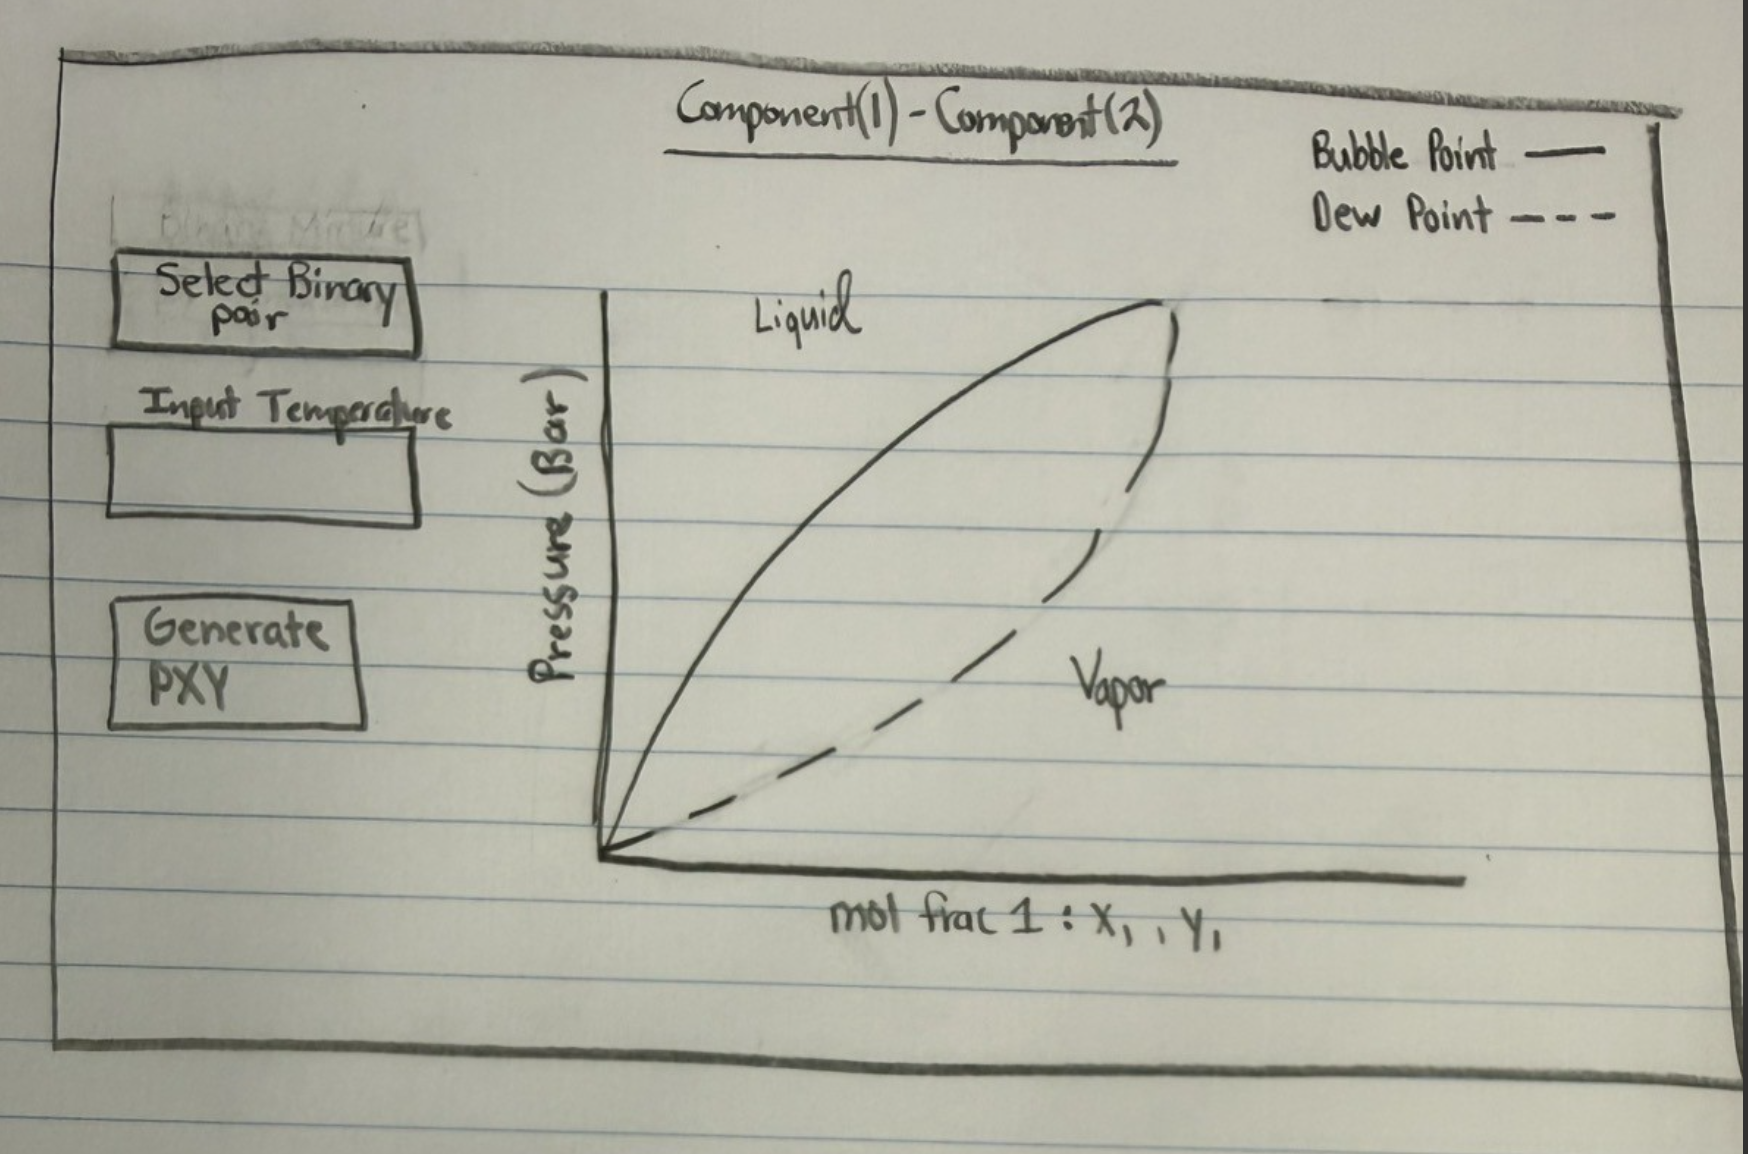

## Section 4: Python Code for the App and GUI

Run the cell below. The app opens in its own window (check the taskbar if it opens behind the browser). The cell keeps running until you close the app window.

In [7]:
"""
P-xy Diagram Generator: binary vapor-liquid equilibrium at constant temperature
CHEE 400 - Project #1

Models
    Ideal       Raoult's law             y_i * P = x_i * Psat_i
    Non-ideal   Modified Raoult's law    y_i * P = x_i * gamma_i * Psat_i
                gamma_i from regular-solution (Scatchard-Hildebrand) theory
    The vapor phase is treated as an ideal gas in both models (low pressure).

Data
    Antoine constants: NIST Chemistry WebBook, SRD 69 (https://webbook.nist.gov)
        log10(Psat / bar) = A - B / (T / K + C)
    Liquid molar volumes and solubility parameters (25 degC): standard
        regular-solution table values. These are NOT on the NIST WebBook,
        which publishes no activity-coefficient parameters.
"""

import csv
import tkinter as tk
from tkinter import filedialog, messagebox, ttk
from tkinter import font as tkfont

import numpy as np
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
from matplotlib.figure import Figure

# =============================================================================
# 1. DATA
# =============================================================================

R_GAS = 8.314462618  # J/(mol K)

# Antoine constants (A, B, C) and their valid range (Tmin, Tmax in K):
#   NIST Chemistry WebBook, "Phase change data" -> "Antoine Equation Parameters".
#   One NIST parameter set is used per component so that every mixture has a
#   single continuous accepted temperature range.
# V     = liquid molar volume at 25 degC, cm3/mol          (regular-solution table)
# delta = solubility parameter at 25 degC, (J/cm3)^0.5     (regular-solution table)
COMPONENTS = {
    "Benzene": {
        "A": 4.01814, "B": 1203.835, "C": -53.226, "Tmin": 287.70, "Tmax": 354.07,
        "ref": "Williamham, Taylor, et al., 1945", "V": 89.0, "delta": 18.8,
    },
    "Toluene": {
        "A": 4.07827, "B": 1343.943, "C": -53.773, "Tmin": 308.52, "Tmax": 384.66,
        "ref": "Williamham, Taylor, et al., 1945", "V": 107.0, "delta": 18.2,
    },
    "n-Pentane": {
        "A": 3.9892, "B": 1070.617, "C": -40.454, "Tmin": 268.8, "Tmax": 341.37,
        "ref": "Osborn and Douslin, 1974", "V": 116.0, "delta": 14.5,
    },
    "n-Hexane": {
        "A": 4.00266, "B": 1171.53, "C": -48.784, "Tmin": 286.18, "Tmax": 342.69,
        "ref": "Williamham, Taylor, et al., 1945", "V": 132.0, "delta": 14.9,
    },
    "n-Heptane": {
        "A": 4.02832, "B": 1268.636, "C": -56.199, "Tmin": 299.07, "Tmax": 372.43,
        "ref": "Williamham, Taylor, et al., 1945", "V": 148.0, "delta": 15.1,
    },
}

# Dropdown entries. Component 1 is the more volatile one, so x1 and y1 on the
# diagram always refer to the light component.
MIXTURES = {
    "Benzene - Toluene": ("Benzene", "Toluene"),
    "n-Hexane - n-Heptane": ("n-Hexane", "n-Heptane"),
    "n-Pentane - n-Hexane": ("n-Pentane", "n-Hexane"),
}

IDEAL = "Ideal (Raoult's law)"
NONIDEAL = "Non-ideal (modified Raoult's law)"
MODELS = (IDEAL, NONIDEAL)

PRESSURE_UNITS = {"bar": 1.0, "kPa": 100.0, "mmHg": 750.0617, "psia": 14.50377}

KELVIN = 273.15

# =============================================================================
# 2. THERMODYNAMICS  (plain functions: no GUI code, easy to check by hand)
# =============================================================================


def psat_bar(name, T_K):
    """Pure-component vapor pressure in bar from the NIST Antoine equation."""
    c = COMPONENTS[name]
    return 10.0 ** (c["A"] - c["B"] / (T_K + c["C"]))


def valid_range_K(comp1, comp2):
    """Temperature range (K) where BOTH components' Antoine constants are valid."""
    t_low = max(COMPONENTS[comp1]["Tmin"], COMPONENTS[comp2]["Tmin"])
    t_high = min(COMPONENTS[comp1]["Tmax"], COMPONENTS[comp2]["Tmax"])
    return t_low, t_high


def activity_coefficients(comp1, comp2, x1, T_K, model):
    """Liquid-phase activity coefficients (gamma1, gamma2).

    Ideal:      gamma1 = gamma2 = 1
    Non-ideal:  regular-solution theory
                phi_i     = x_i V_i / (x1 V1 + x2 V2)          volume fraction
                ln gamma1 = V1 * phi2^2 * (delta1 - delta2)^2 / (R T)
                ln gamma2 = V2 * phi1^2 * (delta1 - delta2)^2 / (R T)
    """
    x1 = np.asarray(x1, dtype=float)
    if model == IDEAL:
        return np.ones_like(x1), np.ones_like(x1)
    V1, d1 = COMPONENTS[comp1]["V"], COMPONENTS[comp1]["delta"]
    V2, d2 = COMPONENTS[comp2]["V"], COMPONENTS[comp2]["delta"]
    x2 = 1.0 - x1
    phi1 = x1 * V1 / (x1 * V1 + x2 * V2)
    phi2 = 1.0 - phi1
    group = (d1 - d2) ** 2 / (R_GAS * T_K)  # mol/cm3
    return np.exp(V1 * phi2**2 * group), np.exp(V2 * phi1**2 * group)


def bubble_point(comp1, comp2, x1, T_K, model):
    """Bubble pressure (bar) and vapor composition y1 for a liquid of composition x1."""
    x1 = np.asarray(x1, dtype=float)
    g1, g2 = activity_coefficients(comp1, comp2, x1, T_K, model)
    p1 = x1 * g1 * psat_bar(comp1, T_K)
    p2 = (1.0 - x1) * g2 * psat_bar(comp2, T_K)
    P = p1 + p2
    return P, p1 / P, g1, g2


def dew_point(comp1, comp2, y1, T_K, model):
    """Dew pressure (bar) and liquid composition x1 for a vapor of composition y1.

    Solved by bisection on x1 until the bubble-point y1(x1) matches the target.
    For the ideal model this reproduces P = 1 / (y1/Psat1 + y2/Psat2).
    """
    low, high = 0.0, 1.0
    for _ in range(60):
        mid = 0.5 * (low + high)
        if bubble_point(comp1, comp2, mid, T_K, model)[1] < y1:
            low = mid
        else:
            high = mid
    x1 = 0.5 * (low + high)
    return float(bubble_point(comp1, comp2, x1, T_K, model)[0]), x1


# =============================================================================
# 3. GUI
# =============================================================================

WINDOW_TITLE = "P-xy Diagram Generator: Binary VLE at Constant Temperature (NIST Antoine data)"

COLOR_BUBBLE = "#1B4F8A"   # liquid / bubble curve
COLOR_DEW = "#B5451B"      # vapor / dew curve
COLOR_REGION = "#E8EEF6"   # two-phase region fill
COLOR_MUTED = "#5F6B7A"
COLOR_ACCENT = "#1B4F8A"


def format_pressure(value):
    """Five significant figures, e.g. 0.31990, 54.320, 407.40."""
    return f"{value:#.5g}".rstrip(".") if value < 1e5 else f"{value:.0f}"


class PxyApp:
    def __init__(self, root):
        self.root = root
        self.root.title(WINDOW_TITLE)
        self.root.minsize(980, 640)

        self.result = None  # filled by generate()
        self.z = 0.50       # cursor composition (mole fraction of component 1)
        self.artists = {}

        base = tkfont.nametofont("TkDefaultFont")
        self.font_bold = base.copy()
        self.font_bold.configure(weight="bold")
        self.font_small = base.copy()
        self.font_small.configure(size=max(base.cget("size") - 1, 8))

        self.root.columnconfigure(1, weight=1)
        self.root.rowconfigure(0, weight=1)

        left = ttk.Frame(self.root, padding=(12, 10, 6, 6))
        left.grid(row=0, column=0, sticky="ns")
        right = ttk.Frame(self.root, padding=(6, 10, 12, 6))
        right.grid(row=0, column=1, sticky="nsew")
        right.columnconfigure(0, weight=1)
        right.rowconfigure(0, weight=1)

        self._build_inputs(left)
        self._build_readout(left)
        self._build_plot(right)
        self._build_constants(right)

        self.status = tk.StringVar(value="Choose a mixture and model, enter a temperature, then generate the diagram.")
        tk.Label(self.root, textvariable=self.status, anchor="w", fg=COLOR_MUTED,
                 padx=12, pady=5).grid(row=1, column=0, columnspan=2, sticky="ew")

        self._on_selection_change()

    # ------------------------------------------------------------------ inputs
    def _build_inputs(self, parent):
        box = ttk.LabelFrame(parent, text="Inputs", padding=10)
        box.pack(fill="x")
        box.columnconfigure(1, weight=1)

        self.mixture_var = tk.StringVar(value=list(MIXTURES)[0])
        self.model_var = tk.StringVar(value=IDEAL)
        self.temp_var = tk.StringVar(value="60")
        self.units_var = tk.StringVar(value="bar")

        tk.Label(box, text="Binary mixture").grid(row=0, column=0, sticky="w", pady=3)
        mixture = ttk.Combobox(box, textvariable=self.mixture_var, values=list(MIXTURES),
                               state="readonly", width=27)
        mixture.grid(row=0, column=1, sticky="ew", padx=(8, 0), pady=3)

        tk.Label(box, text="VLE model").grid(row=1, column=0, sticky="w", pady=3)
        model = ttk.Combobox(box, textvariable=self.model_var, values=MODELS,
                             state="readonly", width=27)
        model.grid(row=1, column=1, sticky="ew", padx=(8, 0), pady=3)

        tk.Label(box, text="Temperature (\u00b0C)").grid(row=2, column=0, sticky="w", pady=3)
        self.temp_entry = tk.Entry(box, textvariable=self.temp_var, width=12)
        self.temp_entry.grid(row=2, column=1, sticky="w", padx=(8, 0), pady=3)
        self.temp_entry.bind("<Return>", lambda event: self.generate())

        self.range_var = tk.StringVar()
        tk.Label(box, textvariable=self.range_var, fg=COLOR_MUTED, font=self.font_small,
                 anchor="w").grid(row=3, column=1, sticky="w", padx=(8, 0))

        tk.Label(box, text="Pressure units").grid(row=4, column=0, sticky="w", pady=3)
        units = ttk.Combobox(box, textvariable=self.units_var, values=list(PRESSURE_UNITS),
                             state="readonly", width=10)
        units.grid(row=4, column=1, sticky="w", padx=(8, 0), pady=3)

        for combo in (mixture, model, units):
            combo.bind("<<ComboboxSelected>>", self._on_selection_change)

        tk.Button(box, text="Generate P-xy diagram", command=self.generate,
                  bg=COLOR_ACCENT, fg="white", activebackground="#163F6E",
                  activeforeground="white", font=self.font_bold, relief="flat",
                  padx=10, pady=6, cursor="hand2").grid(row=5, column=0, columnspan=2,
                                                        sticky="ew", pady=(10, 4))
        exports = ttk.Frame(box)
        exports.grid(row=6, column=0, columnspan=2, sticky="ew")
        exports.columnconfigure((0, 1), weight=1)
        ttk.Button(exports, text="Export data (CSV)", command=self.export_csv).grid(
            row=0, column=0, sticky="ew", padx=(0, 3))
        ttk.Button(exports, text="Save plot (PNG)", command=self.save_plot).grid(
            row=0, column=1, sticky="ew", padx=(3, 0))

    # ----------------------------------------------------------------- readout
    def _build_readout(self, parent):
        box = ttk.LabelFrame(parent, text="Selected point", padding=10)
        box.pack(fill="x", pady=(10, 0))
        box.columnconfigure(1, weight=1)

        self.readout = {}
        self.readout_labels = {}
        layout = [
            ("z", "Composition, z\u2081", None),
            (None, "Bubble point: liquid with x\u2081 = z\u2081", COLOR_BUBBLE),
            ("p_bub", "Pressure", None),
            ("y_bub", "Vapor formed, y\u2081", None),
            ("gamma", "\u03b3\u2081, \u03b3\u2082", None),
            (None, "Dew point: vapor with y\u2081 = z\u2081", COLOR_DEW),
            ("p_dew", "Pressure", None),
            ("x_dew", "Liquid formed, x\u2081", None),
            (None, "Pure components at this temperature", COLOR_MUTED),
            ("psat1", "Psat, component 1", None),
            ("psat2", "Psat, component 2", None),
        ]
        for row, (key, text, color) in enumerate(layout):
            if key is None:  # section heading
                tk.Label(box, text=text, fg=color, font=self.font_bold, anchor="w").grid(
                    row=row, column=0, columnspan=2, sticky="w", pady=(8, 1))
                continue
            label = tk.Label(box, text=text, anchor="w")
            label.grid(row=row, column=0, sticky="w")
            self.readout_labels[key] = label
            self.readout[key] = tk.StringVar(value="-")
            tk.Label(box, textvariable=self.readout[key], font=self.font_bold,
                     anchor="e").grid(row=row, column=1, sticky="e", padx=(12, 0))

    # --------------------------------------------------------------- constants
    def _build_constants(self, parent):
        box = ttk.LabelFrame(
            parent, padding=(10, 6),
            text="NIST Antoine constants in use:  log\u2081\u2080(Psat / bar) = A \u2212 B / (T / K + C)")
        box.grid(row=2, column=0, sticky="ew", pady=(8, 0))
        heads = ("Component", "A", "B", "C", "Valid range (K)", "Source cited by NIST")
        for col, head in enumerate(heads):
            tk.Label(box, text=head, font=self.font_small, fg=COLOR_MUTED).grid(
                row=0, column=col, sticky="w" if col in (0, 5) else "e", padx=(0, 18))
        self.constant_vars = [[tk.StringVar() for _ in heads] for _ in range(2)]
        for r, row_vars in enumerate(self.constant_vars):
            for col, var in enumerate(row_vars):
                tk.Label(box, textvariable=var, font=self.font_small).grid(
                    row=1 + r, column=col, sticky="w" if col in (0, 5) else "e", padx=(0, 18))
        self.regular_var = tk.StringVar()
        tk.Label(box, textvariable=self.regular_var, font=self.font_small, fg=COLOR_MUTED,
                 anchor="w").grid(row=3, column=0, columnspan=len(heads), sticky="w", pady=(5, 0))

    # -------------------------------------------------------------------- plot
    def _build_plot(self, parent):
        self.fig = Figure(figsize=(7.0, 4.8), dpi=100, facecolor="white")
        self.fig.subplots_adjust(left=0.105, right=0.965, top=0.87, bottom=0.115)
        self.ax = self.fig.add_subplot(111)
        self.canvas = FigureCanvasTkAgg(self.fig, master=parent)
        self.plot_widget = self.canvas.get_tk_widget()
        self.plot_widget.configure(takefocus=1, highlightthickness=2,
                                   highlightbackground="#D5DAE1", highlightcolor=COLOR_ACCENT)
        self.plot_widget.grid(row=0, column=0, sticky="nsew")

        tk.Label(parent, fg=COLOR_MUTED, font=self.font_small, anchor="w",
                 text="Move the point: click or drag on the plot, or use \u2190 \u2192 "
                      "(step 0.01).  Shift + arrow steps 0.10.  Home / End jump to 0 and 1."
                 ).grid(row=1, column=0, sticky="ew", pady=(4, 0))

        # Mouse: click or drag sets the composition.
        self.canvas.mpl_connect("button_press_event", self._on_mouse)
        self.canvas.mpl_connect("motion_notify_event", self._on_mouse)
        # Keyboard: arrows nudge the composition (only while the plot has focus,
        # so the arrow keys still work normally inside the temperature box).
        self.plot_widget.bind("<Left>", lambda event: self._step(-0.01))
        self.plot_widget.bind("<Right>", lambda event: self._step(+0.01))
        self.plot_widget.bind("<Shift-Left>", lambda event: self._step(-0.10))
        self.plot_widget.bind("<Shift-Right>", lambda event: self._step(+0.10))
        self.plot_widget.bind("<Home>", lambda event: self._set_z(0.0))
        self.plot_widget.bind("<End>", lambda event: self._set_z(1.0))

        self._draw_empty()

    def _draw_empty(self):
        self.ax.clear()
        self.ax.set_xlim(0, 1)
        self.ax.set_ylim(0, 1)
        self.ax.set_xlabel("Mole fraction of component 1")
        self.ax.set_ylabel("Pressure")
        self.ax.text(0.5, 0.5, "Enter a temperature and select\n\u201cGenerate P-xy diagram\u201d",
                     ha="center", va="center", color=COLOR_MUTED, fontsize=12,
                     transform=self.ax.transAxes)
        self.canvas.draw_idle()

    # ------------------------------------------------------------ input events
    def _on_selection_change(self, event=None):
        """Refresh the accepted-range hint and constants table; redraw if possible."""
        comp1, comp2 = MIXTURES[self.mixture_var.get()]
        t_low, t_high = valid_range_K(comp1, comp2)
        self.range_var.set(f"Accepted: {t_low - KELVIN:.2f} to {t_high - KELVIN:.2f} \u00b0C")

        for row_vars, name in zip(self.constant_vars, (comp1, comp2)):
            c = COMPONENTS[name]
            values = (name, f"{c['A']:.5f}", f"{c['B']:.3f}", f"{c['C']:.3f}",
                      f"{c['Tmin']:.2f} to {c['Tmax']:.2f}", c["ref"])
            for var, value in zip(row_vars, values):
                var.set(value)
        c1, c2 = COMPONENTS[comp1], COMPONENTS[comp2]
        self.regular_var.set(
            "Non-ideal model only (regular-solution theory, 25 \u00b0C, not NIST):   "
            f"\u03b4 = {c1['delta']:.1f}, {c2['delta']:.1f} (J/cm\u00b3)^0.5      "
            f"V = {c1['V']:.0f}, {c2['V']:.0f} cm\u00b3/mol")
        self.readout_labels["psat1"].configure(text=f"Psat, {comp1}")
        self.readout_labels["psat2"].configure(text=f"Psat, {comp2}")

        if self.result is not None and not self.generate(show_errors=False):
            self.status.set("Selection changed. Generate the diagram again to update the plot.")

    def _read_temperature(self, comp1, comp2, show_errors):
        """Return the temperature in K, or None after telling the user what is wrong."""
        t_low, t_high = valid_range_K(comp1, comp2)
        accepted = (f"Accepted range for {self.mixture_var.get()}:\n"
                    f"{t_low - KELVIN:.2f} \u00b0C to {t_high - KELVIN:.2f} \u00b0C   "
                    f"({t_low:.2f} K to {t_high:.2f} K)")
        text = self.temp_var.get().strip()
        try:
            t_c = float(text)
            if not np.isfinite(t_c):
                raise ValueError
        except ValueError:
            if show_errors:
                messagebox.showerror(
                    "Temperature is not a number",
                    f"\u201c{text}\u201d is not a valid temperature. Enter a number in \u00b0C, "
                    f"for example 60.\n\n{accepted}")
                self._focus_temperature()
            return None

        T_K = t_c + KELVIN
        if T_K < t_low - 1e-9 or T_K > t_high + 1e-9:
            if show_errors:
                messagebox.showerror(
                    "Temperature outside the accepted range",
                    f"{t_c:g} \u00b0C is outside the range where the NIST Antoine constants "
                    f"of both components are valid, so the result would be an extrapolation.\n\n"
                    f"{accepted}\n\nEnter a temperature inside this range.")
                self._focus_temperature()
            return None
        return T_K

    def _focus_temperature(self):
        self.temp_entry.focus_set()
        self.temp_entry.selection_range(0, tk.END)

    # --------------------------------------------------------------- calculate
    def generate(self, show_errors=True):
        """Validate the inputs, calculate the P-xy curves and draw them."""
        comp1, comp2 = MIXTURES[self.mixture_var.get()]
        model = self.model_var.get()
        T_K = self._read_temperature(comp1, comp2, show_errors)
        if T_K is None:
            return False

        x1 = np.linspace(0.0, 1.0, 201)
        P, y1, _, _ = bubble_point(comp1, comp2, x1, T_K, model)
        self.result = {
            "mixture": self.mixture_var.get(), "comp1": comp1, "comp2": comp2,
            "model": model, "T_K": T_K, "units": self.units_var.get(),
            "x1": x1, "P": P, "y1": y1,
        }
        if model == NONIDEAL:  # keep Raoult's law as a reference for comparison
            P_ideal, y_ideal, _, _ = bubble_point(comp1, comp2, x1, T_K, IDEAL)
            self.result["P_ideal"], self.result["y_ideal"] = P_ideal, y_ideal

        self._draw_diagram()
        self.plot_widget.focus_set()  # arrow keys work straight away

        message = f"{self.result['mixture']} at {T_K - KELVIN:.2f} \u00b0C, {model}."
        if model == NONIDEAL:
            deviation = 100.0 * (P - P_ideal) / P_ideal
            worst = deviation[np.argmax(np.abs(deviation))]
            message += f"  Largest difference from Raoult's law: {worst:+.2f} % in bubble pressure."
        self.status.set(message)
        return True

    def _draw_diagram(self):
        r = self.result
        k = PRESSURE_UNITS[r["units"]]
        P = r["P"] * k
        ax = self.ax
        ax.clear()

        # Two-phase region = area between the bubble curve P(x1) and dew curve P(y1).
        ax.fill(np.concatenate([r["x1"], r["y1"][::-1]]), np.concatenate([P, P[::-1]]),
                color=COLOR_REGION, zorder=1)
        if "P_ideal" in r:
            ax.plot(r["x1"], r["P_ideal"] * k, color="#8A929C", lw=1.0, ls="--", zorder=2,
                    label="Raoult's law (reference)")
            ax.plot(r["y_ideal"], r["P_ideal"] * k, color="#8A929C", lw=1.0, ls="--", zorder=2)
        ax.plot(r["x1"], P, color=COLOR_BUBBLE, lw=2.2, zorder=3, label="Bubble curve, P vs $x_1$")
        ax.plot(r["y1"], P, color=COLOR_DEW, lw=2.2, zorder=3, label="Dew curve, P vs $y_1$")

        span = P.max() - P.min()
        ax.set_xlim(0, 1)
        ax.set_ylim(P.min() - 0.12 * span, P.max() + 0.12 * span)
        ax.text(0.20, 0.90, "Liquid", transform=ax.transAxes, color=COLOR_MUTED,
                ha="center", va="center", fontsize=11)
        ax.text(0.80, 0.10, "Vapor", transform=ax.transAxes, color=COLOR_MUTED,
                ha="center", va="center", fontsize=11)

        ax.set_xlabel(f"Mole fraction of {r['comp1']}:  $x_1$ (liquid),  $y_1$ (vapor)")
        ax.set_ylabel(f"Pressure ({r['units']})")
        ax.set_title(f"{r['comp1']} (1) - {r['comp2']} (2) at {r['T_K'] - KELVIN:.2f} \u00b0C",
                     fontsize=12, fontweight="bold", pad=26)
        ax.text(0.5, 1.02, r["model"], transform=ax.transAxes, ha="center", va="bottom",
                fontsize=9.5, color=COLOR_MUTED)
        ax.grid(True, color="#DDE2E8", lw=0.6, zorder=0)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        ax.legend(loc="lower right", frameon=False, fontsize=9, bbox_to_anchor=(1.0, 0.16))

        # Cursor artists; their positions are set in _update_cursor().
        a = self.artists
        a["line"] = ax.axvline(self.z, color="#2B2F36", lw=0.9, ls=(0, (4, 3)), zorder=4)
        a["tie_bub"], = ax.plot([], [], color=COLOR_BUBBLE, lw=1.0, ls=":", zorder=4)
        a["tie_dew"], = ax.plot([], [], color=COLOR_DEW, lw=1.0, ls=":", zorder=4)
        a["end_bub"], = ax.plot([], [], "o", ms=6, mfc="white", mec=COLOR_DEW, mew=1.5, zorder=5)
        a["end_dew"], = ax.plot([], [], "o", ms=6, mfc="white", mec=COLOR_BUBBLE, mew=1.5, zorder=5)
        a["pt_bub"], = ax.plot([], [], "o", ms=8, color=COLOR_BUBBLE, mec="white", mew=1.2, zorder=6)
        a["pt_dew"], = ax.plot([], [], "o", ms=8, color=COLOR_DEW, mec="white", mew=1.2, zorder=6)
        self._update_cursor()

    # ------------------------------------------------------------------ cursor
    def _on_mouse(self, event):
        if self.result is None or event.inaxes is not self.ax or event.button != 1:
            return
        self.plot_widget.focus_set()
        self._set_z(round(float(event.xdata), 3))

    def _step(self, amount):
        self._set_z(round(self.z + amount, 2))

    def _set_z(self, z):
        if self.result is None:
            return
        self.z = min(max(z, 0.0), 1.0)
        self._update_cursor()

    def _update_cursor(self):
        """Move the markers to composition z and refresh the numbers beside the plot."""
        r = self.result
        k = PRESSURE_UNITS[r["units"]]
        z = self.z
        args = (r["comp1"], r["comp2"])

        p_bub, y_bub, g1, g2 = bubble_point(*args, z, r["T_K"], r["model"])
        p_dew, x_dew = dew_point(*args, z, r["T_K"], r["model"])
        p_bub, y_bub, p_dew = float(p_bub) * k, float(y_bub), p_dew * k

        a = self.artists
        a["line"].set_xdata([z, z])
        a["pt_bub"].set_data([z], [p_bub])
        a["pt_dew"].set_data([z], [p_dew])
        a["tie_bub"].set_data([z, y_bub], [p_bub, p_bub])   # liquid z  -> its vapor
        a["end_bub"].set_data([y_bub], [p_bub])
        a["tie_dew"].set_data([x_dew, z], [p_dew, p_dew])   # vapor z   -> its liquid
        a["end_dew"].set_data([x_dew], [p_dew])
        self.canvas.draw_idle()

        unit = r["units"]
        self.readout["z"].set(f"{z:.3f}")
        self.readout["p_bub"].set(f"{format_pressure(p_bub)} {unit}")
        self.readout["y_bub"].set(f"{y_bub:.4f}")
        self.readout["gamma"].set(f"{float(g1):.4f}, {float(g2):.4f}")
        self.readout["p_dew"].set(f"{format_pressure(p_dew)} {unit}")
        self.readout["x_dew"].set(f"{x_dew:.4f}")
        self.readout["psat1"].set(f"{format_pressure(psat_bar(r['comp1'], r['T_K']) * k)} {unit}")
        self.readout["psat2"].set(f"{format_pressure(psat_bar(r['comp2'], r['T_K']) * k)} {unit}")

    # ------------------------------------------------------------------ export
    def _need_result(self):
        if self.result is None:
            messagebox.showinfo("Nothing to export yet",
                                "Generate a P-xy diagram first, then export it.")
            return False
        return True

    def _default_filename(self):
        r = self.result
        name = f"Pxy_{r['comp1']}_{r['comp2']}_{r['T_K'] - KELVIN:.1f}C"
        name += "_ideal" if r["model"] == IDEAL else "_nonideal"
        return name.replace(" ", "")

    def export_csv(self):
        if not self._need_result():
            return
        r = self.result
        path = filedialog.asksaveasfilename(
            title="Export P-xy data", defaultextension=".csv",
            initialfile=self._default_filename() + ".csv",
            filetypes=[("CSV file", "*.csv")])
        if not path:
            return
        k, unit = PRESSURE_UNITS[r["units"]], r["units"]
        x1 = np.round(np.linspace(0.0, 1.0, 101), 2)
        P, y1, g1, g2 = bubble_point(r["comp1"], r["comp2"], x1, r["T_K"], r["model"])
        try:
            with open(path, "w", newline="") as handle:
                writer = csv.writer(handle)
                writer.writerow(["P-xy data", f"{r['comp1']} (1) - {r['comp2']} (2)"])
                writer.writerow(["Temperature (degC)", f"{r['T_K'] - KELVIN:.2f}"])
                writer.writerow(["Model", r["model"]])
                writer.writerow(["Antoine constants", "NIST Chemistry WebBook SRD 69"])
                writer.writerow([f"Psat1 ({unit})", f"{psat_bar(r['comp1'], r['T_K']) * k:.6g}"])
                writer.writerow([f"Psat2 ({unit})", f"{psat_bar(r['comp2'], r['T_K']) * k:.6g}"])
                writer.writerow([])
                writer.writerow(["x1", f"P ({unit})", "y1", "gamma1", "gamma2"])
                for row in zip(x1, P * k, y1, g1, g2):
                    writer.writerow([f"{row[0]:.2f}", f"{row[1]:.6g}", f"{row[2]:.5f}",
                                     f"{row[3]:.5f}", f"{row[4]:.5f}"])
        except OSError as error:
            messagebox.showerror("Could not export the data",
                                 f"The file could not be written:\n{error}\n\n"
                                 "Close the file if it is open in Excel, then export again.")
            return
        self.status.set(f"Data exported to {path}")

    def save_plot(self):
        if not self._need_result():
            return
        path = filedialog.asksaveasfilename(
            title="Save plot", defaultextension=".png",
            initialfile=self._default_filename() + ".png",
            filetypes=[("PNG image", "*.png")])
        if not path:
            return
        try:
            self.fig.savefig(path, dpi=200)
        except OSError as error:
            messagebox.showerror("Could not save the plot",
                                 f"The file could not be written:\n{error}")
            return
        self.status.set(f"Plot saved to {path}")


def main():
    try:  # sharper text on high-resolution Windows displays
        from ctypes import windll
        windll.shcore.SetProcessDpiAwareness(1)
    except Exception:
        pass
    root = tk.Tk()
    PxyApp(root)
    root.mainloop()


if __name__ == "__main__":
    main()

## AI Prompting Log:

**AI model used:** Claude 

**Prompt #1:** "Ok I've attached my sample value proposition, app sketch, and app idea of the Pxy chart generator, and all of the documents relevant to the specifications necessary.  I want the user to choose a binary mixture selections from a dropdown menu with benzene-toluene, nhexane-npentane, and nhexane-nheptane.  I want the user to specify a temperature, I want the app to pull constants and any Antoine equation parameter values from NIST website.  I want the program to generate a pxy graph when the user presses calculate.  

*What this did to the code:* It generated the basic code for the binary pair drop down, user entered temperatures, and basic pxy generation using the ideal Raoults law.  

**Prompt #2:** "I would like to make the app slightly more complex than my current idea by allowing for a dropdown menu where the user can select whether to calculate the Pxy graph either by Ideal method or Non ideal method.  I still want the user to enter temperature values, and if the values are not within the valid range of temperatures for the  binary interaction parameters, i want an error message with the accepted range to pop up telling the user to select from the accept range of temperatures.  I want to add a feature where the user can use the mouse or arrows to go to any composition point on the pxy graph curves.  let me know any other suggestions or ways to improve on what i have, and make sure all required specifications are met."

*What this did to the code:* It added another dropdown menu where the user could choose whether to use ideal or nonideal method to generate the Pxy diagram, and it also included an acceptable temperature range that could be inputted.  It also added features that allowed for the data to be exported and saved, and for the plot to be saved.  


**Prompt #3:**  "Can you make it to where it shows all of the numerical values for compositions and pressures at every selected point."

*What this did to the code:* It successfully added a feature to observe the numerical values.  


**Brief Debugging Description:**  I did not have to debug my code because it ran successfully at the beginning and after each change was made.  However, there were times where it used equations or concepts that I did know where they came from.  So, I had to research these concepts on my own in order to verify their correctness.  